=== Annual Hybrid Portfolio Summary (7.5 MW PV + 7.5 MW Wind vs. 25,000 MWh Load) ===
Annual PV Generation:   7,875 MWh
Annual Wind Generation: 15,111 MWh
Gross Renewable Share:  91.9%

 BESS Capacity (MWh)  Power Rating (MW)  Self-Sufficiency (%)  Self-Consumption (%)  BESS Discharge (MWh/yr)  Grid Import (MWh/yr)  Surplus Export (MWh/yr)  Full Cycles (EFC/yr)
                   0                0.0                  75.7                  82.3                        0                  6086                     4072                   0.0
                   5                2.5                  79.5                  86.8                      958                  5127                     3028                 239.6
                  10                5.0                  81.8                  89.5                     1532                  4554                     2403                 191.4
                  20               10.0                  84.3                  92.4                   

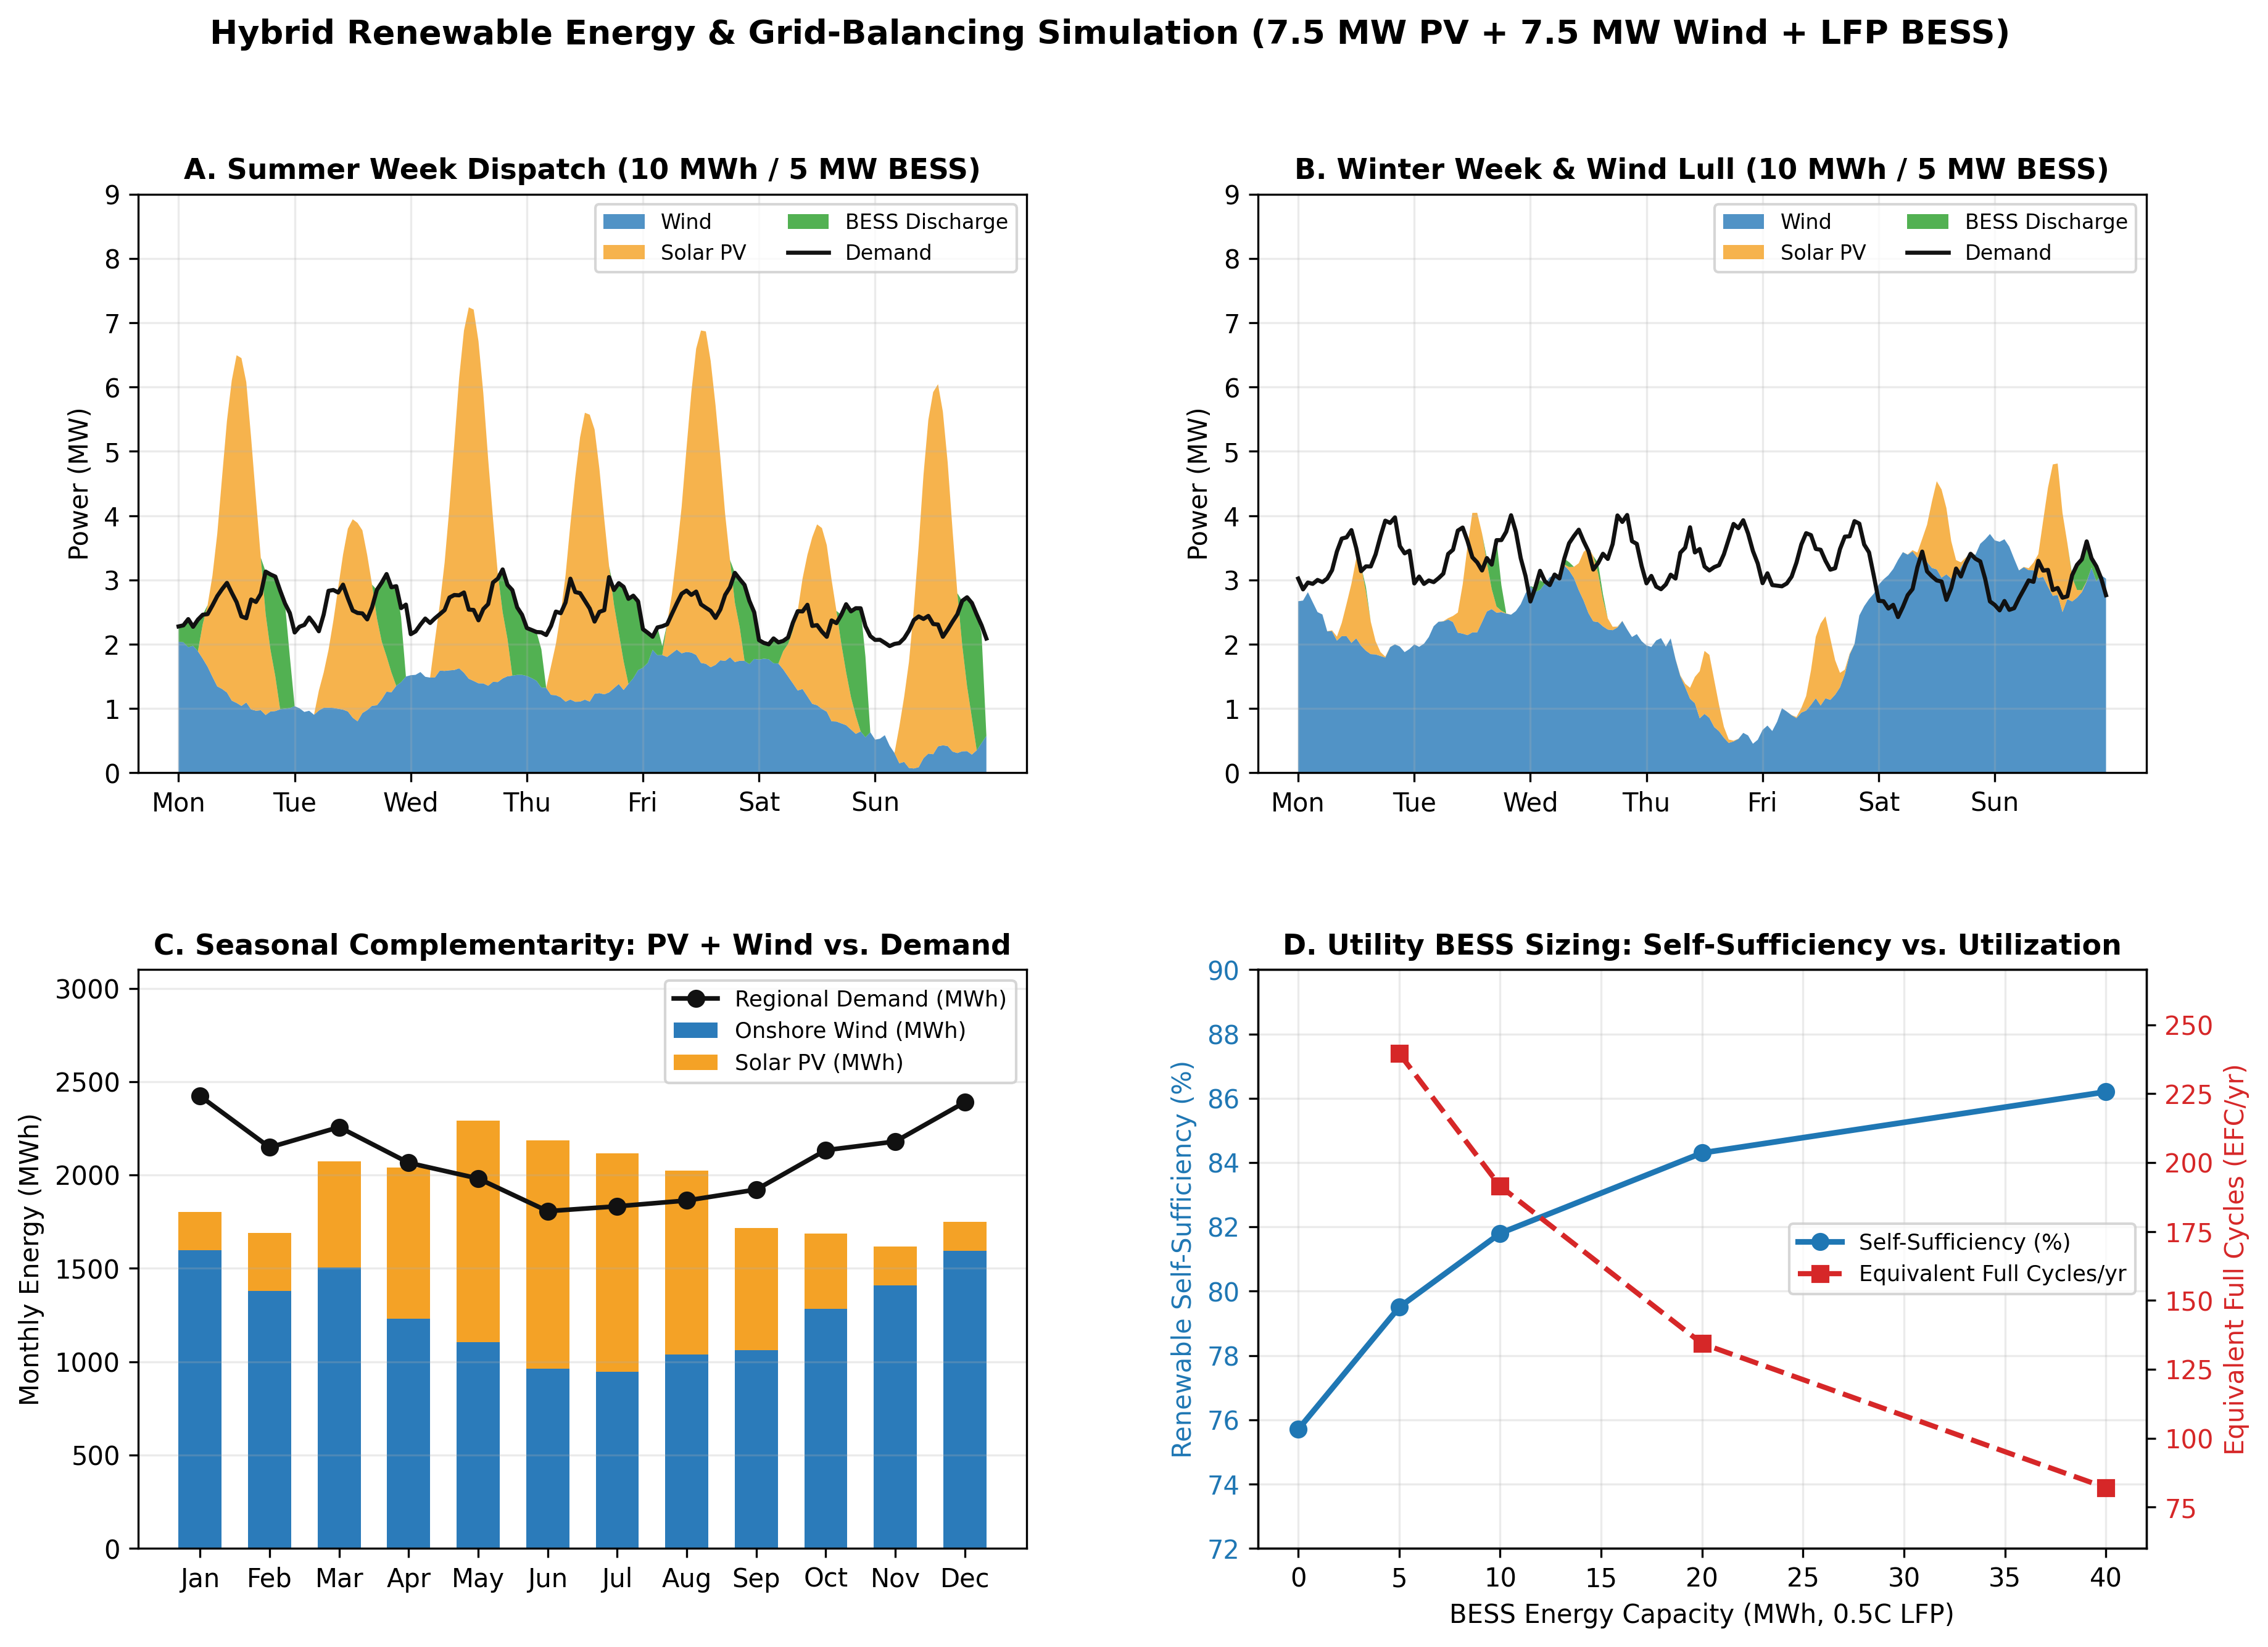

In [4]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# 1. Time index for a standard 8,760-hour year (Bavaria, Germany)
hours = 8760
dt = pd.date_range("2025-01-01", periods=hours, freq="h")
hour_of_day = np.asarray(dt.hour)
day_of_year = np.asarray(dt.dayofyear)
is_weekend = np.asarray(dt.dayofweek >= 5)

rng = np.random.default_rng(42)

# 2. Build hourly regional electricity demand (25,000 MWh/yr)
seasonal_load = 1.0 + 0.14 * np.cos(2 * np.pi * (day_of_year - 15) / 365.0)
diurnal_load = (
    0.82
    + 0.22 * np.exp(-0.5 * ((hour_of_day - 9.5) / 2.3) ** 2)
    + 0.28 * np.exp(-0.5 * ((hour_of_day - 19.0) / 2.5) ** 2)
)
weekend_factor = np.where(is_weekend, 0.88, 1.0)
noise_load = rng.normal(1.0, 0.03, hours)

raw_load = seasonal_load * diurnal_load * weekend_factor * noise_load
load_mw = raw_load * (25000.0 / raw_load.sum())

# 3. Build hourly Solar PV profile (7.5 MWp, ~1,050 kWh/kWp/yr in Bavaria)
pv_cap_mw = 7.5
seasonal_solar = 0.62 + 0.38 * np.sin(2 * np.pi * (day_of_year - 80) / 365.0)
daylight_width = 2.6 + 0.9 * np.sin(2 * np.pi * (day_of_year - 80) / 365.0)
solar_shape = np.exp(-0.5 * ((hour_of_day - 12.5) / daylight_width) ** 2)
solar_shape = np.where((hour_of_day >= 5) & (hour_of_day <= 20), solar_shape, 0.0)

daily_cloud = np.repeat(rng.uniform(0.45, 1.15, 365), 24)
raw_pv = seasonal_solar * solar_shape * daily_cloud
pv_mw = raw_pv * ((pv_cap_mw * 1050.0) / raw_pv.sum())

# 4. Build hourly Onshore Wind profile (7.5 MW, ~23% capacity factor)
wind_cap_mw = 7.5
seasonal_wind = 1.0 + 0.26 * np.cos(2 * np.pi * (day_of_year - 15) / 365.0)
diurnal_wind = 1.0 + 0.08 * np.cos(2 * np.pi * (hour_of_day - 2.0) / 24.0)

t_arr = np.arange(hours)
synoptic = (
    1.0
    + 0.42 * np.sin(2 * np.pi * t_arr / 118.0 + 0.4)
    + 0.30 * np.cos(2 * np.pi * t_arr / 67.0 + 1.7)
    + 0.22 * np.sin(2 * np.pi * t_arr / 215.0 + 2.5)
)
wind_noise = pd.Series(rng.normal(0.0, 0.18, hours)).rolling(6, min_periods=1).mean().to_numpy()
raw_wind = np.clip(seasonal_wind * diurnal_wind * (synoptic + wind_noise), 0.04, None)
wind_mw = raw_wind * ((wind_cap_mw * 8760.0 * 0.23) / raw_wind.sum())

total_ren_mw = pv_mw + wind_mw

# 5. Hourly BESS dispatch simulation (LFP: 92% round-trip efficiency, 0.5C, 10-90% SoC)
def simulate_bess_dispatch(pv, wind, load, cap_mwh, c_rate=0.5, eta_rt=0.92):
    n = len(load)
    eta_c = np.sqrt(eta_rt)
    eta_d = np.sqrt(eta_rt)
    p_max = cap_mwh * c_rate
    soc_min = 0.10 * cap_mwh
    soc_max = 0.90 * cap_mwh
    soc = 0.50 * cap_mwh

    charge_mw = np.zeros(n)
    discharge_mw = np.zeros(n)
    grid_import_mw = np.zeros(n)
    surplus_export_mw = np.zeros(n)
    soc_trace = np.zeros(n)

    net_gen = (pv + wind) - load

    for i in range(n):
        if net_gen[i] >= 0.0:
            p_ch = min(net_gen[i], p_max, max(0.0, (soc_max - soc) / eta_c))
            soc += p_ch * eta_c
            charge_mw[i] = p_ch
            surplus_export_mw[i] = net_gen[i] - p_ch
        else:
            deficit = -net_gen[i]
            p_dis = min(deficit, p_max, max(0.0, (soc - soc_min) * eta_d))
            soc -= p_dis / eta_d
            discharge_mw[i] = p_dis
            grid_import_mw[i] = deficit - p_dis
        soc_trace[i] = soc

    direct_ren_mwh = np.minimum(pv + wind, load).sum()
    total_supplied_ren_mwh = direct_ren_mwh + discharge_mw.sum()
    self_sufficiency_pct = 100.0 * total_supplied_ren_mwh / load.sum()
    self_consumption_pct = 100.0 * (direct_ren_mwh + charge_mw.sum()) / (pv + wind).sum()
    usable_cap = max(1e-9, soc_max - soc_min)
    efc_per_year = discharge_mw.sum() / usable_cap if cap_mwh > 0 else 0.0

    return {
        "cap_mwh": cap_mwh,
        "power_mw": p_max,
        "self_sufficiency_pct": round(self_sufficiency_pct, 1),
        "self_consumption_pct": round(self_consumption_pct, 1),
        "bess_discharge_mwh": round(discharge_mw.sum(), 0),
        "grid_import_mwh": round(grid_import_mw.sum(), 0),
        "surplus_export_mwh": round(surplus_export_mw.sum(), 0),
        "efc_yr": round(efc_per_year, 1),
        "charge_mw": charge_mw,
        "discharge_mw": discharge_mw,
        "grid_import_mw": grid_import_mw,
        "surplus_export_mw": surplus_export_mw,
        "soc_trace": soc_trace,
    }

# 6. Evaluate BESS capacities from 0 MWh (no storage) to 40 MWh
capacities = [0, 5, 10, 20, 40]
results = [simulate_bess_dispatch(pv_mw, wind_mw, load_mw, c) for c in capacities]

summary_df = pd.DataFrame([
    {
        "BESS Capacity (MWh)": r["cap_mwh"],
        "Power Rating (MW)": r["power_mw"],
        "Self-Sufficiency (%)": r["self_sufficiency_pct"],
        "Self-Consumption (%)": r["self_consumption_pct"],
        "BESS Discharge (MWh/yr)": int(r["bess_discharge_mwh"]),
        "Grid Import (MWh/yr)": int(r["grid_import_mwh"]),
        "Surplus Export (MWh/yr)": int(r["surplus_export_mwh"]),
        "Full Cycles (EFC/yr)": r["efc_yr"],
    }
    for r in results
])

print("=== Annual Hybrid Portfolio Summary (7.5 MW PV + 7.5 MW Wind vs. 25,000 MWh Load) ===")
print(f"Annual PV Generation:   {pv_mw.sum():,.0f} MWh")
print(f"Annual Wind Generation: {wind_mw.sum():,.0f} MWh")
print(f"Gross Renewable Share:  {100 * total_ren_mw.sum() / load_mw.sum():.1f}%\n")
print(summary_df.to_string(index=False))

# 7. Generate 4-panel engineering visualization (using 10 MWh / 5 MW BESS as reference case)
ref = results[2]

df_hourly = pd.DataFrame({
    "pv": pv_mw,
    "wind": wind_mw,
    "load": load_mw,
    "bess_dis": ref["discharge_mw"],
    "bess_ch": ref["charge_mw"],
    "grid_import": ref["grid_import_mw"],
}, index=dt)

fig, axes = plt.subplots(2, 2, figsize=(14, 9.5), dpi=300)
plt.subplots_adjust(hspace=0.34, wspace=0.26)

# Panel A: Summer week dispatch (June 9 - June 15)
ax = axes[0, 0]
s_slice = df_hourly.loc["2025-06-09":"2025-06-15"]
x_s = np.arange(len(s_slice))
ax.stackplot(
    x_s,
    s_slice["wind"],
    s_slice["pv"],
    s_slice["bess_dis"],
    labels=["Wind", "Solar PV", "BESS Discharge"],
    colors=["#2b7bba", "#f4a226", "#2ca02c"],
    alpha=0.82,
)
ax.plot(x_s, s_slice["load"], color="#111111", lw=1.6, label="Demand")
ax.set_title("A. Summer Week Dispatch (10 MWh / 5 MW BESS)", fontsize=11, fontweight="bold")
ax.set_ylabel("Power (MW)")
ax.set_xticks(np.arange(0, 168, 24))
ax.set_xticklabels(["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"])
ax.set_ylim(0, 9.0)
ax.grid(alpha=0.25)
ax.legend(loc="upper right", fontsize=8, ncol=2)

# Panel B: Winter week dispatch including low-wind lull (Jan 20 - Jan 26)
ax = axes[0, 1]
w_slice = df_hourly.loc["2025-01-20":"2025-01-26"]
x_w = np.arange(len(w_slice))
ax.stackplot(
    x_w,
    w_slice["wind"],
    w_slice["pv"],
    w_slice["bess_dis"],
    labels=["Wind", "Solar PV", "BESS Discharge"],
    colors=["#2b7bba", "#f4a226", "#2ca02c"],
    alpha=0.82,
)
ax.plot(x_w, w_slice["load"], color="#111111", lw=1.6, label="Demand")
ax.set_title("B. Winter Week & Wind Lull (10 MWh / 5 MW BESS)", fontsize=11, fontweight="bold")
ax.set_ylabel("Power (MW)")
ax.set_xticks(np.arange(0, 168, 24))
ax.set_xticklabels(["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"])
ax.set_ylim(0, 9.0)
ax.grid(alpha=0.25)
ax.legend(loc="upper right", fontsize=8, ncol=2)

# Panel C: Monthly generation complementarity vs. demand
ax = axes[1, 0]
monthly = df_hourly.groupby(df_hourly.index.month).sum()
months = ["Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]
x_m = np.arange(12)
ax.bar(x_m, monthly["wind"], width=0.62, color="#2b7bba", label="Onshore Wind (MWh)")
ax.bar(x_m, monthly["pv"], width=0.62, bottom=monthly["wind"], color="#f4a226", label="Solar PV (MWh)")
ax.plot(x_m, monthly["load"], color="#111111", marker="o", lw=1.8, label="Regional Demand (MWh)")
ax.set_title("C. Seasonal Complementarity: PV + Wind vs. Demand", fontsize=11, fontweight="bold")
ax.set_ylabel("Monthly Energy (MWh)")
ax.set_xticks(x_m)
ax.set_xticklabels(months)
ax.set_ylim(0, 3100)
ax.grid(axis="y", alpha=0.25)
ax.legend(loc="upper right", fontsize=8.5)

# Panel D: Storage sizing trade-off (Self-Sufficiency vs. Cycling)
ax = axes[1, 1]
caps = summary_df["BESS Capacity (MWh)"]
ss = summary_df["Self-Sufficiency (%)"]
efc = summary_df["Full Cycles (EFC/yr)"]

line1 = ax.plot(caps, ss, color="#1f77b4", marker="o", lw=2.2, label="Self-Sufficiency (%)")
ax.set_title("D. Utility BESS Sizing: Self-Sufficiency vs. Utilization", fontsize=11, fontweight="bold")
ax.set_xlabel("BESS Energy Capacity (MWh, 0.5C LFP)")
ax.set_ylabel("Renewable Self-Sufficiency (%)", color="#1f77b4")
ax.tick_params(axis="y", labelcolor="#1f77b4")
ax.set_ylim(72, 90)
ax.grid(alpha=0.25)

ax2 = ax.twinx()
line2 = ax2.plot(caps[1:], efc[1:], color="#d62728", marker="s", ls="--", lw=2.0, label="Equivalent Full Cycles/yr")
ax2.set_ylabel("Equivalent Full Cycles (EFC/yr)", color="#d62728")
ax2.tick_params(axis="y", labelcolor="#d62728")
ax2.set_ylim(60, 270)

lines = line1 + line2
labels = [l.get_label() for l in lines]
ax.legend(lines, labels, loc="center right", fontsize=8.5)

fig.suptitle(
    "Hybrid Renewable Energy & Grid-Balancing Simulation (7.5 MW PV + 7.5 MW Wind + LFP BESS)",
    fontsize=13,
    fontweight="bold",
    y=0.98,
)
plt.savefig("hybrid_pv_wind_bess_dispatch.png", bbox_inches="tight")
plt.show()
